## Use of VAE Recomendation Example:

## VAE Model Architecture Recomendataion:

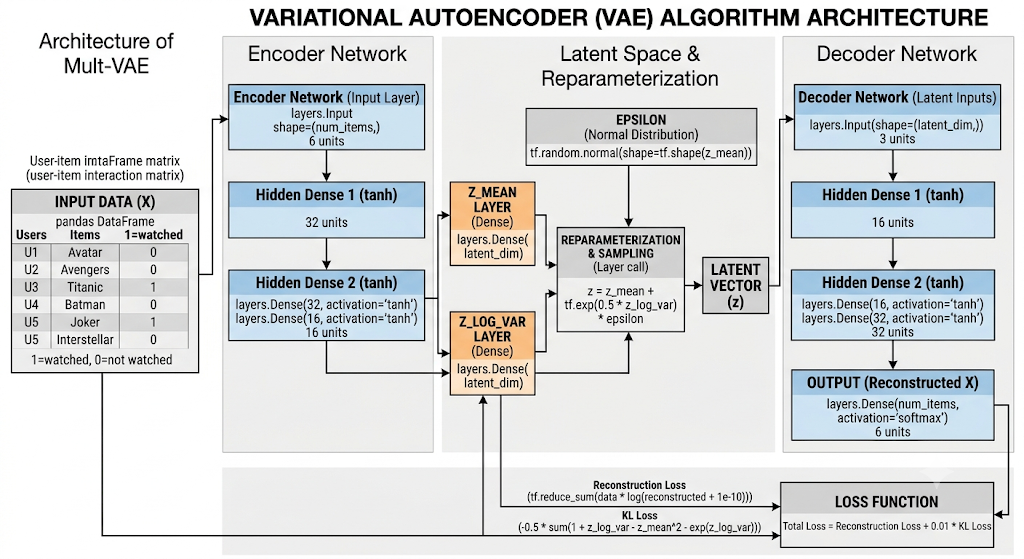

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model

In [16]:
import pandas as pd
df = pd.DataFrame({
    "User": ["U1", "U2", "U3", "U4", "U5"],
    "Avatar": [1, 1, 0, 1, 0],
    "Avengers": [1, 1, 0, 0, 1],
    "Titanic": [0, 0, 1, 0, 1],
    "Batman": [1, 1, 0, 1, 0],
    "Joker": [0, 1, 1, 0, 1],
    "Interstellar": [0, 0, 1, 1, 1]
})
print(df)

  User  Avatar  Avengers  Titanic  Batman  Joker  Interstellar
0   U1       1         1        0       1      0             0
1   U2       1         1        0       1      1             0
2   U3       0         0        1       0      1             1
3   U4       1         0        0       1      0             1
4   U5       0         1        1       0      1             1


### Data Collection Here Discription:

1 = watched

0 = not watched

In [17]:
df.columns

Index(['User', 'Avatar', 'Avengers', 'Titanic', 'Batman', 'Joker',
       'Interstellar'],
      dtype='str')

In [18]:
X = df[['Avatar', 'Avengers', 'Titanic', 'Batman', 'Joker',
        'Interstellar']].to_numpy()
X = X.astype(np.float32)
print(X)
print(type(X))
print(X.shape)

[[1. 1. 0. 1. 0. 0.]
 [1. 1. 0. 1. 1. 0.]
 [0. 0. 1. 0. 1. 1.]
 [1. 0. 0. 1. 0. 1.]
 [0. 1. 1. 0. 1. 1.]]
<class 'numpy.ndarray'>
(5, 6)


In [19]:
X = np.array([
    [1,1,0,1,0,0],
    [1,1,0,1,1,0],
    [0,0,1,0,1,1],
    [1,0,0,1,0,1],
    [0,1,1,0,1,1],
    [1,1,0,0,0,1],
    [0,0,1,1,1,0],
    [1,0,1,0,0,1]
], dtype=np.float32)
print(X)
print(type(X))
print(X.shape)
num_items = X.shape[1]

[[1. 1. 0. 1. 0. 0.]
 [1. 1. 0. 1. 1. 0.]
 [0. 0. 1. 0. 1. 1.]
 [1. 0. 0. 1. 0. 1.]
 [0. 1. 1. 0. 1. 1.]
 [1. 1. 0. 0. 0. 1.]
 [0. 0. 1. 1. 1. 0.]
 [1. 0. 1. 0. 0. 1.]]
<class 'numpy.ndarray'>
(8, 6)


In [20]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

    def compute_output_shape(self, input_shape):
        return input_shape[0]


In [21]:
# Encoder
latent_dim = 3
encoder_inputs = layers.Input(shape=(num_items,))
x = layers.Dense(32,activation='tanh')(encoder_inputs)
x = layers.Dense(16,activation='tanh')(x)

z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

z = Sampling()([z_mean, z_log_var])

encoder = Model(encoder_inputs,[z_mean, z_log_var, z])

In [22]:
#Decoder
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(16,activation='tanh')(latent_inputs)
x = layers.Dense(32,activation='tanh')(x)

outputs = layers.Dense(num_items,activation='softmax')(x)

decoder = Model(latent_inputs,outputs)

In [23]:
# Mult-VAE Model
class MultVAE(Model):
    def __init__(
        self,
        encoder,
        decoder
    ):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = (self.encoder(data))
            reconstructed = (self.decoder(z))
            reconstruction_loss = (
                -tf.reduce_mean(
                    tf.reduce_sum(
                        data *
                        tf.math.log(
                            reconstructed + 1e-10
                        ),
                        axis=1
                    )
                )
            )

            kl_loss = (
                -0.5 *
                tf.reduce_mean(
                    tf.reduce_sum(
                        1 +
                        z_log_var -
                        tf.square(z_mean) -
                        tf.exp(z_log_var),
                        axis=1
                    )
                )
            )

            total_loss = (
                reconstruction_loss
                + 0.01 * kl_loss
            )

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        return {
            "loss": total_loss,
            "reconstruction": reconstruction_loss,
            "kl": kl_loss
        }

In [24]:
# Train
model = MultVAE(encoder,decoder)

model.compile(optimizer='adam')

history = model.fit(
    X,
    epochs=20,
    batch_size=128,
    verbose=1
)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - kl: 0.8356 - loss: 6.1223 - reconstruction: 6.1140
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - kl: 0.7998 - loss: 6.0377 - reconstruction: 6.0297
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - kl: 0.7629 - loss: 6.1362 - reconstruction: 6.1285
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - kl: 0.7330 - loss: 6.2070 - reconstruction: 6.1997
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - kl: 0.7067 - loss: 6.1330 - reconstruction: 6.1259
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - kl: 0.6834 - loss: 6.2471 - reconstruction: 6.2403
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - kl: 0.6606 - loss: 6.1957 - reconstruction: 6.1891
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - kl: 0.6365 - loss: 5.9781 - reconstruction: 5.9718
Epoch 9/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - kl: 0.6126 - loss: 6.0601 - reconstruction: 6.0539
Epoch 10/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - kl: 0.5914 - loss: 5.9409 - reco

In [25]:
# Input to Model
user = np.array(
    [[1,1,0,1,0,0]],
    dtype=np.float32
)

In [26]:
# Predict Model
z_mean, z_log_var, z = (encoder.predict(user))
scores = decoder.predict(z)
print(scores)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
[[0.16081534 0.25987902 0.2424323  0.1428105  0.10999548 0.08406736]]


In [27]:
# Movie names corresponding to the columns in X
movie_names = ['Avatar', 'Avengers', 'Titanic', 'Batman', 'Joker', 'Interstellar']
# Input to Model (User history: watched Avatar, Avengers, Batman)
user = np.array(
    [[1, 1, 0, 1, 0, 0]],
    dtype=np.float32
)
# Predict Model
z_mean, z_log_var, z = encoder.predict(user)
scores = decoder.predict(z)[0]  # Get the 1D score array for our user
# Mask out movies the user has already watched (optional: to recommend *new* movies)
watched_mask = user[0] == 1

print("\n--- Recommendation Results ---")
recommendations = []
for i, movie in enumerate(movie_names):
    status = "Already Watched" if watched_mask[i] else f"Score: {scores[i]:.4f}"
    recommendations.append({"Movie": movie, "Score": scores[i], "Watched": watched_mask[i]})

# Sort recommendations by highest score
recommendations_sorted = sorted(recommendations, key=lambda x: x["Score"], reverse=True)

for rec in recommendations_sorted:
    print(f"{rec['Movie']}: Score = {rec['Score'] * 100:.2f}% {'(Watched)' if rec['Watched'] else '(Recommended)'}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step

--- Recommendation Results ---
Avatar: Score = 25.45% (Watched)
Interstellar: Score = 17.97% (Recommended)
Joker: Score = 17.58% (Recommended)
Batman: Score = 15.65% (Watched)
Titanic: Score = 13.17% (Recommended)
Avengers: Score = 10.18% (Watched)


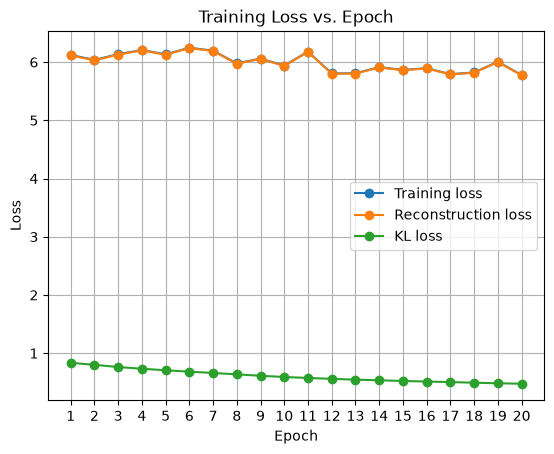

In [28]:
# Xdata Training Epoch vs Loss Graph
import matplotlib.pyplot as plt
epochs = range(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs, history.history["reconstruction"], marker="o", label="Reconstruction loss")
plt.plot(epochs, history.history["kl"], marker="o", label="KL loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs. Epoch")
plt.xticks(epochs)
plt.grid(True)
plt.legend()
plt.show()